# Ejercicio 5: Descenso de Gradiente con Momento (Función de Rosenbrock)
**Matemáticas para Inteligencia Artificial**

Función objetivo:
$$f(x_1, x_2) = (1 - x_1)^2 + 100(x_2 - x_1^2)^2$$

Derivadas parciales (gradiente $\nabla f(x)$):
* $\frac{\partial f}{\partial x_1} = -2(1 - x_1) - 400x_1(x_2 - x_1^2)$
* $\frac{\partial f}{\partial x_2} = 200(x_2 - x_1^2)$

Regla de actualización con momento:
$$x_{i+1} = x_i - \gamma (\nabla f(x_i))^{\top} + \alpha \Delta x_i, \quad \Delta x_i = x_i - x_{i-1} \quad (\Delta x_0 = 0)$$

En este notebook realizaremos:
1. Implementación de $f(x)$, su gradiente $\nabla f(x)$ y el descenso de gradiente con momento.
2. Pruebas heurísticas con varios valores de $\gamma$, $\alpha$ y $x_0$ para observar divergencia, oscilación y convergencia lenta.
3. Ejecución final hasta que $\|\nabla f(x_i)\| < 10^{-6}$ reportando $x^*$, $f(x^*)$, gradiente final e iteraciones.
4. Gráfica de $f(x_i)$ contra $i$.
5. Comparación directa contra el método **sin momento ($\alpha = 0$)** usando los mismos $\gamma$ y $x_0$ (iteraciones, trayectoria y gráfica de $f(x_i)$).


## 1. Importación de librerías, función objetivo, gradiente y algoritmo


In [1]:
import numpy as np              # Para operaciones con vectores y normas
import pandas as pd             # Para resumir pruebas y resultados en tablas
import matplotlib.pyplot as plt # Para graficar convergencia y trayectorias

# Inciso 1: Función de Rosenbrock f(x1, x2) = (1 - x1)^2 + 100*(x2 - x1^2)^2
def f(x):
    x1, x2 = x[0], x[1]
    return (1.0 - x1)**2 + 100.0 * (x2 - x1**2)**2

# Gradiente analítico de f(x1, x2)
def gradiente(x):
    x1, x2 = x[0], x[1]
    df_dx1 = -2.0 * (1.0 - x1) - 400.0 * x1 * (x2 - x1**2)
    df_dx2 = 200.0 * (x2 - x1**2)
    return np.array([df_dx1, df_dx2], dtype=float)

# Función reutilizable de Descenso de Gradiente con Momento
# (Si alpha = 0.0 se obtiene el descenso de gradiente clásico sin momento)
def descenso_gradiente_momento(x0, gamma, alpha=0.0, tolerancia=1e-6, max_iter=40000):
    x = np.array(x0, dtype=float)
    delta_x = np.zeros_like(x)   # En i = 0 no hay paso previo (Delta x_0 = 0)
    historial = []
    estado = "No convergió (límite de iteraciones)"

    for i in range(max_iter):
        grad = gradiente(x)
        norma_grad = np.linalg.norm(grad)
        valor_f = f(x)

        # Detección de divergencia
        if np.isnan(norma_grad) or np.isinf(norma_grad) or norma_grad > 1e12:
            estado = "Diverge"
            break

        historial.append({
            "i": i,
            "x1": x[0],
            "x2": x[1],
            "grad_x1": grad[0],
            "grad_x2": grad[1],
            "||grad||": norma_grad,
            "f(x_i)": valor_f
        })

        # Criterio de paro: ||gradiente|| < tolerancia
        if norma_grad < tolerancia:
            estado = "Converge"
            break

        # Regla de actualización con momento
        x_siguiente = x - gamma * grad + alpha * delta_x
        delta_x = x_siguiente - x
        x = x_siguiente

    return pd.DataFrame(historial), estado

## 2. Selección heurística de $\gamma$, $\alpha$ y $x_0$


In [2]:
# Inciso 2a: Probamos distintos valores de gamma (fijando x0 = [-1.2, 1.0] y alpha = 0.9)
x0_base = [-1.2, 1.0]
gammas_prueba = [0.01, 0.005, 0.002, 0.001, 0.0005, 0.0001]

resultados_gamma = []
for g in gammas_prueba:
    df_p, estado = descenso_gradiente_momento(x0_base, gamma=g, alpha=0.9, tolerancia=1e-6, max_iter=40000)
    ultima = df_p.iloc[-1]
    resultados_gamma.append({
        "gamma": g,
        "Estado": estado,
        "Iteraciones": int(ultima["i"]),
        "f(x) final": f"{ultima['f(x_i)']:.2e}",
        "||grad|| final": f"{ultima['||grad||']:.2e}"
    })

print("Pruebas variando gamma (con x0 = [-1.2, 1.0], alpha = 0.9):")
tabla_gammas = pd.DataFrame(resultados_gamma)
tabla_gammas

Pruebas variando gamma (con x0 = [-1.2, 1.0], alpha = 0.9):


,gamma,Estado,Iteraciones,f(x) final,||grad|| final
0,0.0100,Diverge,3,1.54e+14,5.54e+11
1,0.0050,Diverge,5,3.79e+09,1.94e+08
2,0.0020,Converge,1549,1.25e-12,9.98e-07
3,0.0010,Converge,3020,1.25e-12,9.98e-07
4,0.0005,Converge,6242,1.25e-12,1.00e-06
5,0.0001,Converge,31922,1.25e-12,1.00e-06


In [3]:
# Inciso 2b: Probamos distintos valores de momento alpha (fijando gamma = 0.001 y x0 = [-1.2, 1.0])
alphas_prueba = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99]

resultados_alpha = []
for a in alphas_prueba:
    df_p, estado = descenso_gradiente_momento(x0_base, gamma=0.001, alpha=a, tolerancia=1e-6, max_iter=40000)
    ultima = df_p.iloc[-1]
    resultados_alpha.append({
        "alpha": a,
        "Estado": estado,
        "Iteraciones": int(ultima["i"]),
        "f(x) final": f"{ultima['f(x_i)']:.2e}",
        "||grad|| final": f"{ultima['||grad||']:.2e}"
    })

print("Pruebas variando alpha (con gamma = 0.001, x0 = [-1.2, 1.0]):")
tabla_alphas = pd.DataFrame(resultados_alpha)
tabla_alphas

Pruebas variando alpha (con gamma = 0.001, x0 = [-1.2, 1.0]):


,alpha,Estado,Iteraciones,f(x) final,||grad|| final
0,0.00,Converge,32076,1.25e-12,1.00e-06
1,0.50,Converge,16014,1.25e-12,9.99e-07
2,0.80,Converge,6329,1.25e-12,9.99e-07
3,0.90,Converge,3020,1.25e-12,9.98e-07
4,0.95,Converge,1324,1.23e-12,9.93e-07
5,0.99,Converge,3185,2.64e-15,8.84e-07


In [4]:
# Inciso 2c: Probamos distintos puntos iniciales x0 (fijando gamma = 0.001 y alpha = 0.95)
puntos_iniciales = [
    [-1.2, 1.0],
    [0.0, 0.0],
    [2.0, 2.0],
    [-2.0, 3.0],
    [3.0, 3.0]
]

resultados_x0 = []
for x0_p in puntos_iniciales:
    df_p, estado = descenso_gradiente_momento(x0_p, gamma=0.001, alpha=0.95, tolerancia=1e-6, max_iter=40000)
    ultima = df_p.iloc[-1]
    resultados_x0.append({
        "x0": str(x0_p),
        "Estado": estado,
        "Iteraciones": int(ultima["i"]),
        "x* encontrado": f"[{ultima['x1']:.4f}, {ultima['x2']:.4f}]" if estado == "Converge" else "N/A",
        "f(x*)": f"{ultima['f(x_i)']:.2e}" if estado == "Converge" else "N/A"
    })

print("Pruebas variando x0 (con gamma = 0.001, alpha = 0.95):")
tabla_x0 = pd.DataFrame(resultados_x0)
tabla_x0

Pruebas variando x0 (con gamma = 0.001, alpha = 0.95):


,x0,Estado,Iteraciones,x* encontrado,f(x*)
0,"[-1.2, 1.0]",Converge,1324,"[1.0000, 1.0000]",1.23e-12
1,"[0.0, 0.0]",Converge,1210,"[1.0000, 1.0000]",1.23e-12
2,"[2.0, 2.0]",Diverge,8,N/A,N/A
3,"[-2.0, 3.0]",Converge,1342,"[1.0000, 1.0000]",1.24e-12
4,"[3.0, 3.0]",Diverge,3,N/A,N/A


### Conclusión de la selección heurística
* **Elección de $\gamma = 0.001$:**
  * Con $\gamma = 0.01$ y $\gamma = 0.005$ el método **diverge** de inmediato debido a la gran pendiente de las paredes del valle (el factor $100$ en $(x_2 - x_1^2)^2$).
  * Con $\gamma = 0.0001$ converge, pero **muy lento** (31,922 iteraciones incluso con momento).
  * Con $\gamma = 0.001$ la convergencia es estable tanto **con momento** como **sin momento**, lo que permite hacer una comparación limpia y justa entre ambos métodos.
* **Elección de $\alpha = 0.95$:**
  * Conforme aumenta $\alpha$ desde $0.0$ hasta $0.95$, el número de iteraciones cae drásticamente (de 32,076 a **1,324**).
  * Al subir demasiado el momento ($\alpha = 0.99$), el exceso de inercia provoca **oscilaciones** alrededor del valle y las iteraciones vuelven a subir (3,185). Por ello $\alpha = 0.95$ ofrece el mejor equilibrio.
* **Elección de $x_0 = (-1.2, 1.0)$:**
  * Es un punto clásico para evaluar la función de Rosenbrock porque obliga al algoritmo a recorrer el valle curvo desde el lado izquierdo hasta $(1, 1)$. Puntos donde el gradiente inicial es muy grande (como $(2, 2)$ o $(3, 3)$) divergen con $\alpha = 0.95$ por el término cúbico y la inercia acumulada.
* **Límite de iteraciones:** Se eligió `max_iter = 40000` porque el descenso sin momento necesita algo más de 32,000 iteraciones para alcanzar $\|\nabla f(x_i)\| < 10^{-6}$ con $\gamma = 0.001$.


## 3. Ejecución final con momento y reporte del mínimo encontrado


In [5]:
# Inciso 3: Ejecutamos el descenso de gradiente CON MOMENTO usando los parámetros elegidos
x0_elegido = [-1.2, 1.0]
gamma_elegido = 0.001
alpha_elegido = 0.95
tolerancia = 1e-6

tabla_momento, estado_mom = descenso_gradiente_momento(
    x0_elegido, gamma=gamma_elegido, alpha=alpha_elegido, tolerancia=tolerancia, max_iter=40000
)

final_mom = tabla_momento.iloc[-1]

print("=== RESULTADO FINAL CON MOMENTO (EJERCICIO 5) ===")
print(f"Estado:               {estado_mom}")
print(f"Parámetros elegidos:  gamma = {gamma_elegido}, alpha = {alpha_elegido}, x0 = {x0_elegido}")
print(f"Iteraciones totales:  {int(final_mom['i'])}")
print(f"Mínimo encontrado x*: [{final_mom['x1']:.6f}, {final_mom['x2']:.6f}]")
print(f"Valor mínimo f(x*):   {final_mom['f(x_i)']:.2e}")
print(f"Gradiente final:      [{final_mom['grad_x1']:.2e}, {final_mom['grad_x2']:.2e}]")
print(f"Norma del gradiente:  {final_mom['||grad||']:.2e}")

=== RESULTADO FINAL CON MOMENTO (EJERCICIO 5) ===
Estado:               Converge
Parámetros elegidos:  gamma = 0.001, alpha = 0.95, x0 = [-1.2, 1.0]
Iteraciones totales:  1324
Mínimo encontrado x*: [0.999999, 0.999998]
Valor mínimo f(x*):   1.23e-12
Gradiente final:      [-4.43e-07, -8.89e-07]
Norma del gradiente:  9.93e-07


## 4. Gráfica de $f(x_i)$ contra $i$ (con momento)


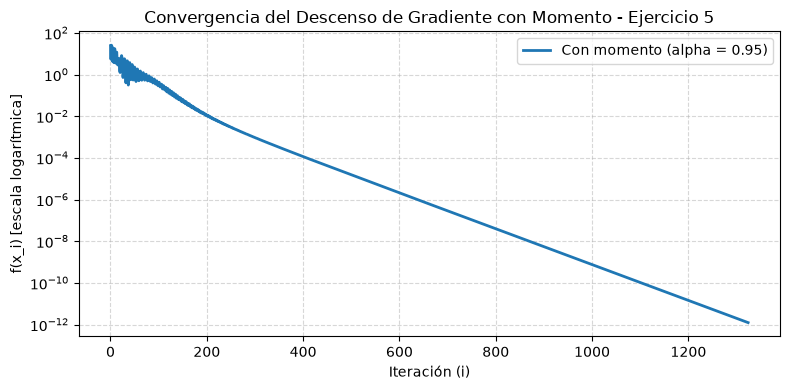

In [6]:
# Inciso 4: Gráfica de convergencia f(x_i) contra iteración i (en escala logarítmica para ver el detalle)
plt.figure(figsize=(8, 4))
plt.plot(tabla_momento["i"], tabla_momento["f(x_i)"], linewidth=2, color="tab:blue", label="Con momento (alpha = 0.95)")
plt.yscale("log") # Escala logarítmica porque f(x_i) baja desde ~24 hasta ~10^-12

plt.title("Convergencia del Descenso de Gradiente con Momento - Ejercicio 5")
plt.xlabel("Iteración (i)")
plt.ylabel("f(x_i) [escala logarítmica]")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Comparación: Con momento ($\alpha = 0.95$) vs. Sin momento ($\alpha = 0$)


In [7]:
# Ejecutamos el método SIN MOMENTO (alpha = 0.0) con exactamente los mismos gamma y x0
tabla_sin_momento, estado_sin = descenso_gradiente_momento(
    x0_elegido, gamma=gamma_elegido, alpha=0.0, tolerancia=tolerancia, max_iter=40000
)

final_sin = tabla_sin_momento.iloc[-1]

# Tabla comparativa directa
comparacion = pd.DataFrame([
    {
        "Método": f"Con momento (alpha = {alpha_elegido})",
        "Estado": estado_mom,
        "Iteraciones": int(final_mom["i"]),
        "x* encontrado": f"[{final_mom['x1']:.6f}, {final_mom['x2']:.6f}]",
        "f(x*)": f"{final_mom['f(x_i)']:.2e}",
        "||grad|| final": f"{final_mom['||grad||']:.2e}"
    },
    {
        "Método": "Sin momento (alpha = 0.0)",
        "Estado": estado_sin,
        "Iteraciones": int(final_sin["i"]),
        "x* encontrado": f"[{final_sin['x1']:.6f}, {final_sin['x2']:.6f}]",
        "f(x*)": f"{final_sin['f(x_i)']:.2e}",
        "||grad|| final": f"{final_sin['||grad||']:.2e}"
    }
])

factor_aceleracion = final_sin["i"] / final_mom["i"]
print(f"Aceleración lograda con momento: {factor_aceleracion:.1f}x menos iteraciones")
comparacion

Aceleración lograda con momento: 24.2x menos iteraciones


,Método,Estado,Iteraciones,x* encontrado,f(x*),||grad|| final
0,Con momento (alpha = 0.95),Converge,1324,"[0.999999, 0.999998]",1.23e-12,9.93e-07
1,Sin momento (alpha = 0.0),Converge,32076,"[0.999999, 0.999998]",1.25e-12,1.00e-06


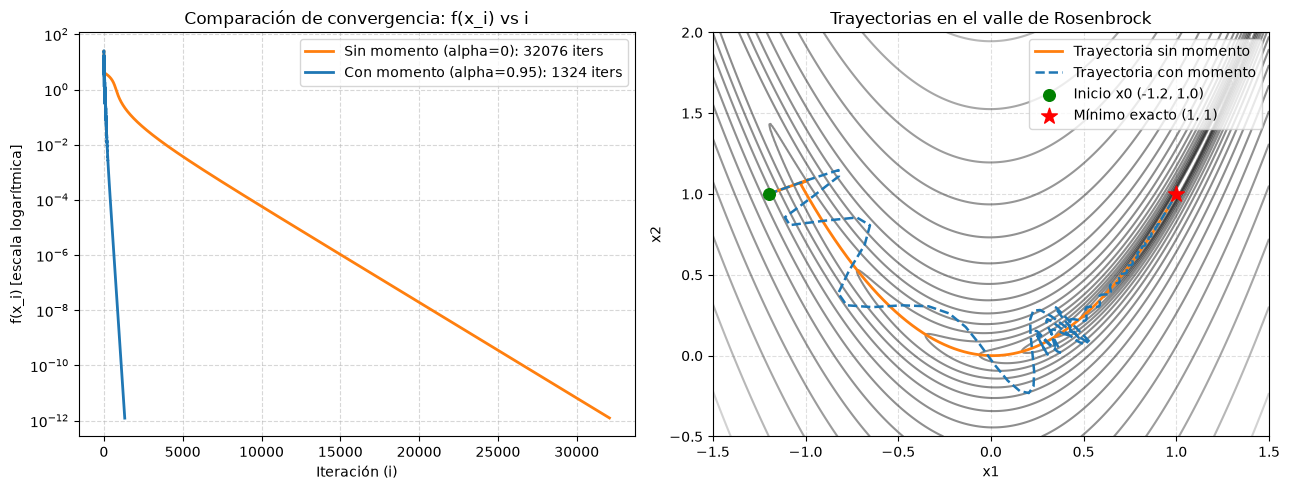

In [8]:
# Gráficas comparativas: (1) Curva de f(x_i) vs i y (2) Trayectoria sobre las curvas de nivel de Rosenbrock
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Gráfica 1: Comparación de f(x_i) contra i ---
axes[0].plot(tabla_sin_momento["i"], tabla_sin_momento["f(x_i)"], linewidth=2, color="tab:orange", label=f"Sin momento (alpha=0): {int(final_sin['i'])} iters")
axes[0].plot(tabla_momento["i"], tabla_momento["f(x_i)"], linewidth=2, color="tab:blue", label=f"Con momento (alpha={alpha_elegido}): {int(final_mom['i'])} iters")
axes[0].set_yscale("log")
axes[0].set_title("Comparación de convergencia: f(x_i) vs i")
axes[0].set_xlabel("Iteración (i)")
axes[0].set_ylabel("f(x_i) [escala logarítmica]")
axes[0].grid(True, which="both", linestyle="--", alpha=0.5)
axes[0].legend()

# --- Gráfica 2: Comparación de trayectorias en el plano (x1, x2) ---
# Creamos una malla para dibujar las curvas de nivel de la función de Rosenbrock
x1_grid = np.linspace(-1.5, 1.5, 300)
x2_grid = np.linspace(-0.5, 2.0, 300)
X1, X2 = np.meshgrid(x1_grid, x2_grid)
Z = (1.0 - X1)**2 + 100.0 * (X2 - X1**2)**2

niveles = np.logspace(-1, 3, 20)
axes[1].contour(X1, X2, Z, levels=niveles, cmap="gray", alpha=0.45)

# Dibujamos ambas trayectorias
axes[1].plot(tabla_sin_momento["x1"], tabla_sin_momento["x2"], color="tab:orange", linewidth=2, label="Trayectoria sin momento")
axes[1].plot(tabla_momento["x1"], tabla_momento["x2"], color="tab:blue", linewidth=1.8, linestyle="--", label="Trayectoria con momento")

# Marcamos el punto inicial y el mínimo global (1, 1)
axes[1].scatter([x0_elegido[0]], [x0_elegido[1]], color="green", s=70, zorder=5, label="Inicio x0 (-1.2, 1.0)")
axes[1].scatter([1.0], [1.0], color="red", marker="*", s=140, zorder=6, label="Mínimo exacto (1, 1)")

axes[1].set_title("Trayectorias en el valle de Rosenbrock")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()

### ¿Cuánto influye el momento en la convergencia?
La influencia del momento es **enorme** en esta función:
1. **Número de iteraciones:** Con los mismos $\gamma = 0.001$ y $x_0 = (-1.2, 1.0)$, el descenso clásico sin momento necesita **32,076 iteraciones**, mientras que con momento ($\alpha = 0.95$) solo necesita **1,324 iteraciones** (es **~24.2 veces más rápido**, reduciendo el esfuerzo en un **95.9%**).
2. **Trayectoria:** La función de Rosenbrock tiene un valle parabólico muy estrecho y plano en el fondo ($x_2 \approx x_1^2$). Sin momento, el gradiente a lo largo del valle es muy pequeño y el método avanza casi a paso de tortuga. Con momento, el algoritmo acumula "velocidad" en la dirección consistente del valle y amortigua el zig-zag contra las paredes empinadas, aunque realiza un pequeño sobreimpulso inicial antes de encarrilarse rápido hacia $(1, 1)$.
3. **Gráfica de $f(x_i)$:** En escala logarítmica se observa que la curva con momento cae casi verticalmente hasta $10^{-12}$, mientras que la curva sin momento desciende con una pendiente muchísimo más lenta durante decenas de miles de iteraciones.
